In [2]:
using CairoMakie, JLD2

In [3]:
filename = "err1_low, err2_low, err1_high, err2_high_D_fixe20,g_low 2,g_high 10anharmonic.jld2"
@load filename errorTN_g
err1_low, err2_low, err1_high, err2_high = errorTN_g

([3.9286640197332244e-14], [1.8442482081986573e-15], [3.244629780212625e-14], [1.1486569885214642e-15])

┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264


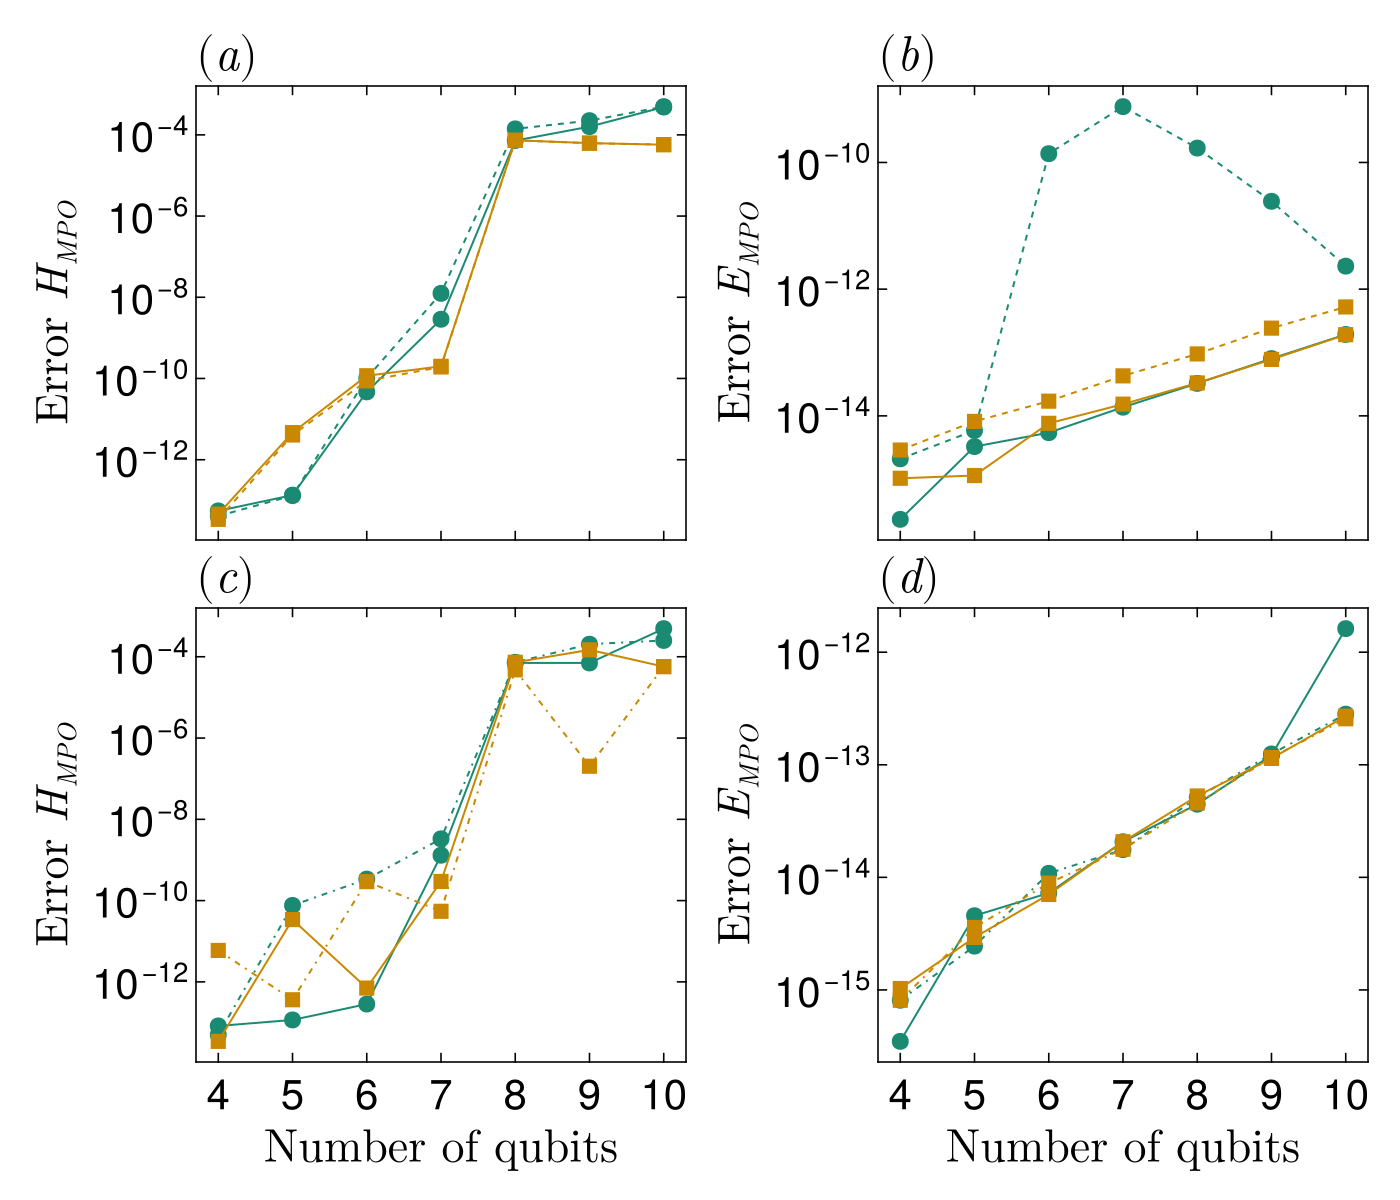

In [ ]:


CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false,
        ygridvisible = false,
        xlabelsize = 23,
        ylabelsize = 23,
        titlesize = 24,
        xticklabelsize = 21,
        yticklabelsize = 21,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        xminorticksize = 2.5,
        yminorticksize = 2.5,
        xminorticksvisible = false,
        yminorticksvisible = false,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
        xticklabelpad = 3,
        yticklabelpad = 3,
		xtickalign = 1,
		ytickalign = 1,
		xminortickalign = 1,
		yminortickalign = 1,
		xticksmirrored = true,
		yticksmirrored = true,
    ),
))


N_list = 4:10

D_low   = 10
D_high  = 30
D_fixed = 20
g_low   = 2
g_high  = 10
g_fixed = 5

potentials = Dict(
    "Harmonic" => "harmonic",
    "Random"   => "random_potential"
)


palette = Dict(
    "Harmonic" => RGBf(0.788, 0.533, 0.0),   # ← quad color
    "Random"   => RGBf(0.106, 0.541, 0.447),    # ← random color
)

markers = Dict(
    "Harmonic" => :rect,
    "Random"   => :circle,
)


fig = Figure(resolution = (700, 600), backgroundcolor = :white)

ax1 = Axis(fig[1,1],
    ylabel = L"Error $H_{MPO}$",
    yscale = log10,
    title = L"(a)", titlealign = :left, titlegap = 2,
)

ax2 = Axis(fig[1,2],
    ylabel = L"Error $E_{MPO}$",
    yscale = log10,
    title = L"(b)", titlealign = :left, titlegap = 2,
)

ax3 = Axis(fig[2,1],
    xlabel = L"Number of qubits$$",
    ylabel = L"Error $H_{MPO}$",
    yscale = log10,
    title = L"(c)", titlealign = :left, titlegap = 2,
)

ax4 = Axis(fig[2,2],
    xlabel = L"Number of qubits$$",
    ylabel = L"Error $E_{MPO}$",
    yscale = log10,
    title = L"(d)", titlealign = :left, titlegap = 2,
)

# Link x axes, hide top row x decorations
CairoMakie.linkxaxes!(ax1, ax2, ax3, ax4)
CairoMakie.hidexdecorations!(ax1, ticks = false, minorticks = false)
CairoMakie.hidexdecorations!(ax2, ticks = false, minorticks = false)

for (label, suffix) in potentials
    c  = palette[label]
    mk = markers[label]

    filename  = "err1_low, err2_low, err1_high, err2_high_D_low$(D_low),D_high$(D_high),g_fixed$(g_fixed)$(suffix).jld2"
    filename2 = "err1_low, err2_low, err1_high, err2_high_D_low$(D_low),D_high$(D_high),g_fixed$(g_fixed)$(suffix) (1).jld2"

    @load filename  errorTN_g
    err1_low, err2_low, err1_high, err2_high = errorTN_g
    @load filename2 errorTN_g
    err1_low2, err2_low2, err1_high2, err2_high2 = errorTN_g

    err1_low  = [err1_low...;  err1_low2...]
    err2_low  = [err2_low...;  err2_low2...]
    err1_high = [err1_high...; err1_high2...]
    err2_high = [err2_high...; err2_high2...]

    for (ax, yh, yl) in [(ax1, err1_high, err1_low), (ax2, err2_high, err2_low)]
        lines!(ax, N_list, yh; color = c, linewidth = 1.0, linestyle = :solid)
        scatter!(ax, N_list, yh; color = c, marker = mk, markersize = 12, strokewidth = 0)
        lines!(ax, N_list, yl; color = c, linewidth = 1.0, linestyle = :dash)
        scatter!(ax, N_list, yl; color = c, marker = mk, markersize = 12, strokewidth = 0)
    end
end

for (label, suffix) in potentials
    c  = palette[label]
    mk = markers[label]

    filename  = "err1_low, err2_low, err1_high, err2_high_D_fixe$(D_fixed),g_low $(g_low),g_high $(g_high)$(suffix).jld2"
    filename2 = "err1_low, err2_low, err1_high, err2_high_D_fixe$(D_fixed),g_low $(g_low),g_high $(g_high)$(suffix) (1).jld2"

    @load filename  errorTN_g
    err1_low, err2_low, err1_high, err2_high = errorTN_g
    @load filename2 errorTN_g
    err1_low2, err2_low2, err1_high2, err2_high2 = errorTN_g

    err1_low  = [err1_low...;  err1_low2...]
    err2_low  = [err2_low...;  err2_low2...]
    err1_high = [err1_high...; err1_high2...]
    err2_high = [err2_high...; err2_high2...]

    for (ax, yh, yl) in [(ax3, err1_high, err1_low), (ax4, err2_high, err2_low)]
        lines!(ax, N_list, yh; color = c, linewidth = 1.0, linestyle = :solid)
        scatter!(ax, N_list, yh; color = c, marker = mk, markersize = 12, strokewidth = 0)
        lines!(ax, N_list, yl; color = c, linewidth = 1.0, linestyle = :dashdot)
        scatter!(ax, N_list, yl; color = c, marker = mk, markersize = 12, strokewidth = 0)
    end
end

CairoMakie.colgap!(fig.layout, 14)
CairoMakie.rowgap!(fig.layout, 6)

save("error_analysis_PRL.pdf", fig)
fig